In [63]:
from langgraph.graph import START , END , StateGraph
from typing import TypedDict
import os
from tools import query_generator_tool, rag_pipeline_tool, select_tool

In [64]:
class AgentState(TypedDict):
  question : str
  answer : str
  next_node : str
  db_files : list
  text_files : list
  status : str
  tool : str  

In [ ]:
# tools
# def select_tool(question):
#   '''code of select tool'''
#   tool = 'rag_tool' 
#   #query_generator_tool
#   return tool

# def select_db_files(question):
#   '''code of selected db files tool which takes decision based on file description and filenames'''
#   select_db_files = ['employees_dataset.csv']
#   return select_db_files

# def query_generator_tool(files , question):
#   '''query generator on multiple files code (first do for single file then later multiple)'''
#   answer = 'some random answer from query generator'
#   return answer
  
# def rag_pipeline_tool(question):
#   '''RAG pipeline code to generate the answer'''
#   answer = 'some random ans from rag_pipeline'
#   return answer

def routing_function(state : AgentState):
  return state['next_node']

In [66]:
#agents
def Supervisor_Agent(state : AgentState):
  if not state['status']:
    return {'next_node' : 'Select_Agent'}
  if state['status'] == 'select_agent_done':
    if state['tool'] == 'rag_pipeline_tool':
      return {'next_node' : 'Files_Agent'}
    else:
      return {'next_node' : 'DB_Agent'} 
  return {'next_node' : 'END'}

def Select_Agent(state : AgentState):
  '''code for select tool'''
  question = state['question']
  #tool = 'rag_tool'
  tool = select_tool(question)
  return {'status':'select_agent_done','tool': tool}

def DB_Agent(state : AgentState):
    question = state['question']
    #db_files = selected_db_files(question)
    #answer = query_generator_tool(selected_db_files,question)
    generated_code , result =query_generator_tool(question)
    return {'answer': str(result),'status':'db_agent_done'}

def Files_Agent(state: AgentState):
    question = state['question']
    answer = rag_pipeline_tool(question)
    return {'answer': answer,'status':'files_agent_done'}



In [67]:
graph = StateGraph(AgentState)
graph.add_node('Supervisor_Agent', Supervisor_Agent)
graph.add_node('DB_Agent', DB_Agent)
graph.add_node('Files_Agent', Files_Agent)
graph.add_node('Select_Agent', Select_Agent)

graph.add_edge(START, 'Supervisor_Agent')
graph.add_conditional_edges('Supervisor_Agent', routing_function,
                            {'Supervisor_Agent':'Supervisor_Agent', 
                             'DB_Agent': 'DB_Agent', 
                             'Files_Agent': 'Files_Agent',
                             'Select_Agent':'Select_Agent', 
                             'END': END})
graph.add_edge('DB_Agent', 'Supervisor_Agent')
graph.add_edge('Files_Agent', 'Supervisor_Agent')
graph.add_edge('Select_Agent', 'Supervisor_Agent') 
app = graph.compile()

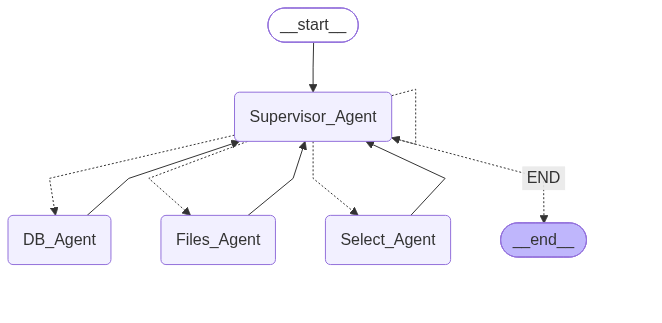

In [68]:
app

In [69]:
output = app.invoke({'question': 'How many employees live in Chennai?','status':''})

In [70]:
output

{'question': 'How many employees live in Chennai?',
 'answer': '1',
 'next_node': 'END',
 'status': 'db_agent_done',
 'tool': 'query_generator_tool'}

In [71]:
# 1. Database/CSV Question
output_db = app.invoke({
    'question': 'How many employees r in the db?',
    'status': ''
})
print("DB Output Answer:", output_db.get('answer'))

# 2. PDF Question
output_rag = app.invoke({
    'question': 'How do I set up Android Lollipop?',
    'status': ''
})
print("RAG Output Answer:", output_rag.get('answer'))

DB Output Answer: 10
RAG Output Answer: **Setting up Android 5.0 Lollipop**

1. **Power on the device** and follow the on‑screen prompts.  
2. **Connect to Wi‑Fi** when asked – this lets the device download the latest updates.  
3. **Sign in to your Google account** (or create one) to sync contacts, apps, and settings.  
4. **Accept the terms of service** and choose your preferred privacy options.  
5. **Set up security** – choose a PIN, pattern, password, or fingerprint if supported.  
6. **Configure Google services** (e.g., backup, location, voice search) as desired.  
7. **Choose a screen lock and optional screen‑lock recovery options**.  
8. **Select your preferred home screen layout** and add widgets or shortcuts.  
9. **Finish the wizard**; the device will complete any pending system updates automatically.

**Checking the Android version (optional)**  
- Open **Settings → System → About phone** (or **About tablet**).  
- Look for **Android version** or tap **System updates** to v

In [72]:
output_db = app.invoke({
    'question': 'who has the least salary and howmuch?',
    'status': ''
})
print("DB Output Answer:", output_db.get('answer'))

DB Output Answer: {'name': 'Nirlaj', 'salary': 18000}


In [75]:
output_rag = app.invoke({
    'question': 'How do I change my wallpaper?',
    'status': ''
})
print("RAG Output Answer:", output_rag.get('answer'))

RAG Output Answer: 1. Touch and hold the home‑screen background.  
2. Tap **Wallpapers**.  
3. Swipe left or right to select a wallpaper, or choose an image from **Photos**, **Downloads**, or **Drive**.  
4. Tap the desired image to set it as your wallpaper.
